# Ablation: full Hao reference without the HaoSub cells

In [1]:
import hashlib
import anndata
import numpy as np
import pandas as pd
import rectanglepy as rp
from scipy.sparse import csr_matrix, issparse
import helper

## Hyperparameter sensitivity

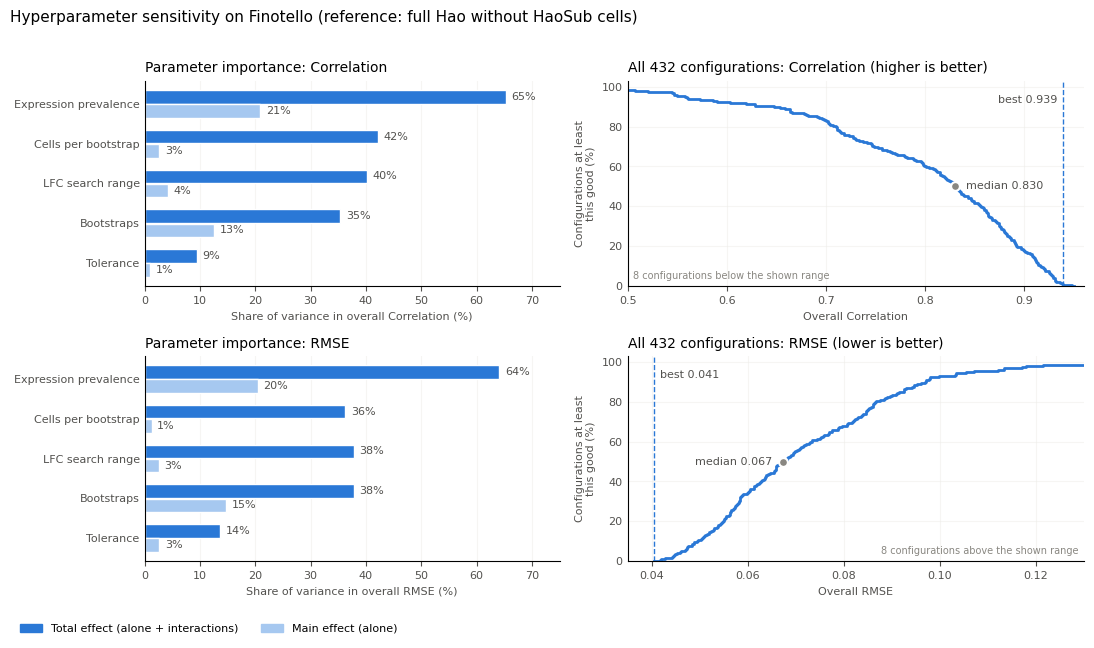

Share of configurations with r >= 0.9: 18%; within 0.01 of the best r: 4%


,Correlation main effect (%),Correlation total effect (%),RMSE main effect (%),RMSE total effect (%)
parameter,,,,
Expression prevalence,20.9,65.3,20.4,64.1
Cells per bootstrap,2.6,42.1,1.3,36.3
LFC search range,4.3,40.2,2.6,37.8
Bootstraps,12.6,35.4,14.7,37.9
Tolerance,1.0,9.4,2.7,13.7


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# the grid is a full factorial (3 x 4 x 3 x 3 x 4 = 432), so variance shares come straight from group means:
# main effect  = Var(E[Y | parameter]) / Var(Y)            -> the parameter alone
# total effect = 1 - Var(E[Y | all other parameters]) / Var(Y) -> the parameter plus all its interactions
grid = pd.read_csv('../data/ablation/finotello_hyperparameter_search_hao_disjoint.csv')
best = grid.loc[grid['combined_position'].idxmin()]
parameter_names = {
    'prevalence': 'Expression prevalence',
    'cells_per_bootstrap': 'Cells per bootstrap',
    'lfc_range': 'LFC search range',
    'bootstraps': 'Bootstraps',
    'tolerance': 'Tolerance',
}
metrics = [('overall_correlation', 'Correlation'), ('overall_rmse', 'RMSE')]

def variance_shares(metric):
    total_variance = grid[metric].var(ddof=0)
    rows = []
    for parameter in parameter_names:
        others = [p for p in parameter_names if p != parameter]
        main = grid.groupby(parameter)[metric].transform('mean').var(ddof=0) / total_variance
        total = 1 - grid.groupby(others)[metric].transform('mean').var(ddof=0) / total_variance
        rows.append((parameter, main, total))
    return pd.DataFrame(rows, columns=['parameter', 'main', 'total']).set_index('parameter')

sensitivity = pd.concat({metric: variance_shares(metric) for metric, _ in metrics}, axis=1)
order = sensitivity[('overall_correlation', 'total')].sort_values().index  # largest at the top

total_color, main_color, ink, muted = '#2a78d6', '#a6c8f0', '#52514e', '#898781'
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), facecolor='white', gridspec_kw={'width_ratios': [1, 1.1]})

for row, (metric, metric_name) in enumerate(metrics):
    # left: how much of the variance across the grid each parameter explains
    ax = axes[row, 0]
    shares = sensitivity[metric].loc[order] * 100
    y = np.arange(len(order))
    ax.barh(y + 0.18, shares['total'], height=0.34, color=total_color, edgecolor='white', linewidth=1)
    ax.barh(y - 0.18, shares['main'], height=0.34, color=main_color, edgecolor='white', linewidth=1)
    for yi, (total, main) in enumerate(zip(shares['total'], shares['main'])):
        ax.annotate(f'{total:.0f}%', (total, yi + 0.18), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=8, color=ink)
        ax.annotate(f'{main:.0f}%', (main, yi - 0.18), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=8, color=ink)
    ax.set_yticks(y)
    ax.set_yticklabels([parameter_names[p] for p in order], fontsize=9)
    ax.set_xlim(0, 75)
    ax.set_xlabel(f'Share of variance in overall {metric_name} (%)', fontsize=8, color=ink)
    ax.set_title(f'Parameter importance: {metric_name}', fontsize=10, loc='left')
    ax.grid(axis='x', color='#eeede9', linewidth=0.8)
    ax.set_axisbelow(True)

    # right: share of all 432 configurations that are at least as good as a given value
    ax = axes[row, 1]
    values = np.sort(grid[metric].to_numpy())
    if metric == 'overall_correlation':
        share_as_good = 1 - np.arange(len(values)) / len(values)          # share with r >= value
    else:
        share_as_good = np.arange(1, len(values) + 1) / len(values)        # share with RMSE <= value
    ax.step(values, share_as_good * 100, where='post' if metric == 'overall_rmse' else 'pre',
            color=total_color, linewidth=2)
    median = grid[metric].median()
    lower_is_better = metric == 'overall_rmse'
    inward = 1 if lower_is_better else -1  # labels sit on the side facing the bulk of the curve
    ax.axvline(best[metric], color=total_color, linestyle='--', linewidth=1)
    ax.annotate(f'best {best[metric]:.3f}', (best[metric], 96), xytext=(4 * inward, 0), textcoords='offset points',
                ha='left' if lower_is_better else 'right', va='top', fontsize=8, color=ink)
    ax.scatter([median], [50], s=40, color=muted, edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(f'median {median:.3f}', (median, 50), xytext=(-8 * inward, 0), textcoords='offset points',
                ha='right' if lower_is_better else 'left', va='center', fontsize=8, color=ink)
    low, high = (0.5, 0.96) if metric == 'overall_correlation' else (0.035, 0.13)
    outside = int(((grid[metric] < low) | (grid[metric] > high)).sum())
    ax.set_xlim(low, high)
    ax.annotate(f'{outside} configurations {"above" if lower_is_better else "below"} the shown range',
                (1 if lower_is_better else 0, 0), xycoords='axes fraction', xytext=(-4 * inward, 4),
                textcoords='offset points', ha='right' if lower_is_better else 'left', va='bottom',
                fontsize=7, color=muted)
    ax.set_ylim(0, 103)
    ax.set_xlabel(f'Overall {metric_name}', fontsize=8, color=ink)
    ax.set_ylabel('Configurations at least\nthis good (%)', fontsize=8, color=ink)
    direction = 'higher' if metric == 'overall_correlation' else 'lower'
    ax.set_title(f'All 432 configurations: {metric_name} ({direction} is better)', fontsize=10, loc='left')
    ax.grid(color='#eeede9', linewidth=0.8)
    ax.set_axisbelow(True)

for ax in axes.flat:
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8, colors=ink)
    ax.tick_params(axis='y', length=0)

fig.legend(handles=[Patch(color=total_color, label='Total effect (alone + interactions)'),
                    Patch(color=main_color, label='Main effect (alone)')],
           loc='lower left', ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.01, -0.01))
fig.suptitle('Hyperparameter sensitivity on Finotello (reference: full Hao without HaoSub cells)',
             fontsize=11, x=0.01, ha='left')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig('../output/ablation_fino_parameter_importance.png', dpi=300, bbox_inches='tight')
plt.show()

summary = sensitivity.mul(100).round(1)
summary.columns = [f'{metric_name} {effect} effect (%)' for (metric, effect), metric_name in
                   zip(summary.columns, ['Correlation'] * 2 + ['RMSE'] * 2)]
summary = summary.loc[order[::-1]].rename(index=parameter_names)
summary.to_csv('../output/ablation_fino_parameter_importance.csv')
print(f"Share of configurations with r >= 0.9: {(grid['overall_correlation'] >= 0.9).mean():.0%}; "
      f"within 0.01 of the best r: {(grid['overall_correlation'] >= best['overall_correlation'] - 0.01).mean():.0%}")
summary

### Supplementary: one parameter changed at a time from the best configuration

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 432-configuration grid search (Finotello, full Hao without HaoSub), copied from
# rectangle_benchmark/output/finotello_hyperparameter_search_hao_disjoint/results_ranked.csv
grid = pd.read_csv('../data/ablation/finotello_hyperparameter_search_hao_disjoint.csv')
best = grid.loc[grid['combined_position'].idxmin()]

parameters = [
    ('bootstraps', 'Bootstraps', [7, 12, 20]),
    ('cells_per_bootstrap', 'Cells per bootstrap', [100, 250, 500, 1000]),
    ('prevalence', 'Expression prevalence', [0.4, 0.5, 0.6]),
    ('lfc_range', 'LFC search range', ['lower', 'original', 'higher']),
    ('tolerance', 'Tolerance', [0.01, 0.03, 0.05, 0.1]),
]
metrics = [
    ('overall_correlation', 'Correlation', (0.5, 0.96)),
    ('overall_rmse', 'RMSE', (0.035, 0.13)),
]

# one-at-a-time: change one parameter from the best configuration, hold the other four fixed
def neighbourhood(parameter):
    others = [p for p, _, _ in parameters if p != parameter]
    rows = grid[(grid[others] == best[others]).all(axis=1)]
    return rows.set_index(parameter)

best_color, grid_color, line_color, ink = '#2a78d6', '#c3c2b7', '#2a78d6', '#52514e'
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, len(parameters), figsize=(13, 5.6), sharey='row', facecolor='white')
for col, (parameter, title, levels) in enumerate(parameters):
    local = neighbourhood(parameter)
    for row, (metric, metric_name, (low, high)) in enumerate(metrics):
        ax = axes[row, col]
        x = np.arange(len(levels))
        for xi, level in zip(x, levels):
            values = grid.loc[grid[parameter] == level, metric].to_numpy()
            # values outside the shared axis are pinned to the edge as triangles
            clipped = np.clip(values, low, high)
            outside = clipped != values
            jitter = rng.uniform(-0.18, 0.18, len(values))
            ax.scatter(xi + jitter[~outside], clipped[~outside], s=6, color=grid_color, linewidth=0, zorder=1)
            if outside.any():
                ax.scatter(xi + jitter[outside], clipped[outside], s=14, color=grid_color, linewidth=0,
                           marker='v' if metric == 'overall_correlation' else '^', zorder=1, clip_on=False)
        ax.axhline(best[metric], color=best_color, linestyle='--', linewidth=1, zorder=2)
        ax.plot(x, local.loc[levels, metric], color=line_color, linewidth=2, zorder=3)
        ax.scatter(x, local.loc[levels, metric], s=40, color=line_color, edgecolor='white', linewidth=1.5, zorder=4)
        ax.set_ylim(low, high)
        ax.set_xticks(x)
        ax.set_xticklabels([str(level) for level in levels], fontsize=8, color=ink)
        ax.set_xlim(-0.5, len(levels) - 0.5)
        ax.grid(axis='y', color='#eeede9', linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        ax.tick_params(axis='y', labelsize=8, colors=ink)
        if row == 0:
            ax.set_title(title, fontsize=10)
        if col == 0:
            ax.set_ylabel(f'Overall {metric_name}', fontsize=9)

legend_handles = [
    Line2D([], [], color=line_color, linewidth=2, marker='o', markersize=6, markeredgecolor='white',
           label='One parameter changed from the best configuration'),
    Line2D([], [], color=best_color, linestyle='--', linewidth=1, label='Best configuration'),
    Line2D([], [], color=grid_color, linestyle='none', marker='o', markersize=4, label='All 432 configurations'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, frameon=False, fontsize=8,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Hyperparameter sensitivity on Finotello (reference: full Hao without HaoSub cells)',
             fontsize=11, x=0.01, ha='left')
fig.text(0.01, 0.925, 'Triangles: configurations outside the shown range, pinned to the axis edge.', fontsize=8, color=ink)
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
plt.savefig('../output/ablation_fino_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Best configuration: {best['configuration']} "
      f"(r={best['overall_correlation']:.3f}, RMSE={best['overall_rmse']:.3f})")

# Cell-type level ablation on all Figure 2 datasets

Same references as Figure 2: **HaoSub** for the human datasets (Finotello, Hoek, Morandini, Dietrich) and **Tabula Muris** for the mouse datasets (Chen, Petitprez).

How to run:
1. Run the setup cell below.
2. Run each ablation cell. Every cell deconvolves all six datasets and writes `../output/ablation_hao_sub/<ablation>/<dataset>.csv`.
3. Ablations marked **requires modified rectanglepy**: apply the source change, restart the kernel, run the setup cell and only that ablation cell, then revert the change before the next one.
4. The evaluation and plot cells only read the saved CSVs, so they can be run in a fresh kernel. Missing ablations are skipped with a warning.

In [1]:
from pathlib import Path
import anndata
import numpy as np
import pandas as pd
import rectanglepy as rp
from anndata import AnnData
import helper
print(rp.__version__)

ablation_root = Path('../output/ablation_hao_sub')

adata_hao_sub = anndata.read_h5ad('../data/fig2/haoSub_adata.h5ad')
sc_data_muris = pd.read_pickle('../data/sc_data_tabula_muris.pkl.zip')
annotations_muris = pd.read_csv('../data/annotations_tabula_muris.csv', index_col=0)['0']
annotations_muris = pd.Series(annotations_muris, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations_muris.to_frame(name='cell_type'))

# dataset -> (reference, bulks as samples x genes), same pairing as figure_2.ipynb
ablation_datasets = {
    'finotello': (adata_hao_sub, pd.read_csv('../data/fig2/finotello/bulks_finotello_tpm.csv', index_col=0).T),
    'petitprez': (adata_muris, pd.read_csv('../data/fig2/bulks/bulks_petitprez_tpm.csv', index_col=0).T),
    'chen': (adata_muris, pd.read_csv('../data/fig2/bulks/bulks_chen_tpm.csv', index_col=0).T),
    'hoek': (adata_hao_sub, pd.read_csv('../data/fig2/bulks/bulks_hoek_tpm.csv', index_col=0).T),
    'morandini': (adata_hao_sub, pd.read_csv('../data/fig2/morandini/morandini_rework_tpm.csv.gz', index_col=0).T),
    'dietrich': (adata_hao_sub, pd.read_csv('../data/fig2/deconvMe/dietrich_tpm.csv', index_col=0).T),
}

def run_ablation(ablation, datasets=None, **rectangle_kwargs):
    out_dir = ablation_root / ablation
    out_dir.mkdir(parents=True, exist_ok=True)
    for dataset in datasets or ablation_datasets:
        reference, bulks = ablation_datasets[dataset]
        print(f'--- {ablation}: {dataset}')
        estimations, _ = rp.rectangle(reference, bulks, **rectangle_kwargs)
        estimations.to_csv(out_dir / f'{dataset}.csv')

1.6.0


In [3]:
# Full Rectangle (default settings)
import shutil
figure_2_estimations = {
    'finotello': '../output/hao_estimations_fino.csv',
    'petitprez': '../output/muris_estimations_peti.csv',
    'chen': '../output/muris_estimations_chen.csv',
    'hoek': '../output/hao_estimations_hoek.csv',
    'morandini': '../output/hao_estimations_morandini.csv',
    'dietrich': '../output/hao_estimations_dietrich.csv',
}
(ablation_root / 'full').mkdir(parents=True, exist_ok=True)
for dataset, path in figure_2_estimations.items():
    shutil.copyfile(path, ablation_root / 'full' / f'{dataset}.csv')

In [4]:
run_ablation('no_mrna_bias', correct_mrna_bias=False)

--- no_mrna_bias: finotello


2026-10-08 10:05:21.288 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 10:05:23.533 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:05:27.305 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 10:05:30.862 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 10:05:32.298 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 10:05:33.952 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 10:05:35.121 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 10:05:37.554 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:05:50.583 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02751286572342514, Pearson R:0.9126771923666832 for p=0.05, lfc=1.75
2026-10-08 10:05:50.677 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-08 10:09:14.090 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 21
2026-10-08 10:09:14.193 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.10102211572443362, Pearson R:0.3575404734446003 for p=0.05, lfc=2.25
2026-10-08 10:09:14.282 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:09:14.409 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.10132839914544109, Pearson R:0.3624041203060426 for p=0.05, lfc=2.5
2026-10-08 10:09:14.505 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25
2026-10-08 10:09:14.626 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.10153798278888145, Pearson R:0.3619291732526262 for p=0.05, lfc=2.75
2026-10-08 10:09:14.693 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:09:14.806 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.10222478127677995, Pearson R:0.35561960750838684 for p=0.05, lfc=3.0
2026-10-08 10:09:14.810 | INFO     | rectanglepy.pp.create_signature:_de_analysis:232 - Optimization done
 Best cutoffs  p: 0.05 and lfc: 1.5
2026-10-08 10:09:14.915 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-08 10:09:14.923 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:385 - Starting rectangle cluster analysis
2026-10-08 10:09:14.934 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:290 - Starting clustered analysis
2026-10-08 10:09:16.311 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:09:19.694 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-08 10:09:21.079 | INFO     | rectanglepy.pp.create_signature:_run_dese

In [5]:
run_ablation('no_grid_search', optimize_cutoffs=False)

--- no_grid_search: finotello


2026-10-08 10:09:40.150 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 10:09:43.928 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:09:47.599 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 10:09:49.615 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 10:09:51.559 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 10:09:53.634 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 10:09:54.916 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 10:09:56.133 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 10:10:27.457 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 2
2026-10-08 10:10:27.482 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 0
2026-10-08 10:10:27.501 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 8
2026-10-08 10:10:27.550 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 6
2026-10-08 10:10:27.556 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 3
2026-10-08 10:10:27.561 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 5
2026-10-08 10:10:27.586 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 7
2026-10-08 10:10:27.595 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 4
2026-10-08 10:10:27.599 | INFO   

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-08 10:13:38.305 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 41
2026-10-08 10:13:38.330 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 40
2026-10-08 10:13:38.341 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 48
2026-10-08 10:13:38.355 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 49
2026-10-08 10:13:38.442 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 43
2026-10-08 10:13:38.453 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 50


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 10:13:38.518 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 42
2026-10-08 10:13:38.554 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 51
2026-10-08 10:13:38.584 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 44
2026-10-08 10:13:38.642 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 45
2026-10-08 10:13:38.656 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 53
2026-10-08 10:13:38.667 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 52


Polishing not needed - no active set detected at optimal point


2026-10-08 10:13:38.732 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 47
2026-10-08 10:13:38.747 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 54
2026-10-08 10:13:38.919 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 46
2026-10-08 10:13:39.003 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 55
2026-10-08 10:13:39.241 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 49
2026-10-08 10:13:39.255 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 48
2026-10-08 10:13:39.270 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 56
2026-10-08 10:13:39.277 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 57
2026-10-08 10:13:39.278 | IN

In [2]:
# requires modified rectanglepy: unknown content correction switched off
run_ablation('no_unknown')

--- no_unknown: finotello


2026-10-08 10:15:16.020 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 10:15:18.147 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:15:21.964 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 10:15:24.773 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 10:15:26.051 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 10:15:27.732 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 10:15:28.945 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 10:15:30.771 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:15:44.132 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-08 10:15:44.261 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02751286572342514, Pearson R:0.9126771923666832 for p=0.05, lfc=1.75
2026-10-08 10:15:44.353 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

...

2026-10-08 10:19:15.881 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 51
2026-10-08 10:19:15.984 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 52
2026-10-08 10:19:16.005 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 54
2026-10-08 10:19:16.032 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 53


no unknown


2026-10-08 10:19:16.097 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 55


no unknown
no unknown
no unknown


2026-10-08 10:19:16.362 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 56
2026-10-08 10:19:16.391 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 57
2026-10-08 10:19:16.421 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 58


In [2]:
# requires modified rectanglepy: hierarchical (recursive) deconvolution switched off
run_ablation('no_hierarchy')

--- no_hierarchy: finotello


2026-10-08 10:20:35.712 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 10:20:37.690 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:20:40.880 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 10:20:43.527 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 10:20:44.869 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 10:20:46.521 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 10:20:47.701 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 10:20:48.816 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:21:00.665 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02751286572342514, Pearson R:0.9126771923666832 for p=0.05, lfc=1.75
2026-10-08 10:21:00.745 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-08 10:24:15.535 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 42
2026-10-08 10:24:15.538 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 46
2026-10-08 10:24:15.548 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 43
2026-10-08 10:24:15.575 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 49
2026-10-08 10:24:15.582 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 50
2026-10-08 10:24:15.585 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 51
2026-10-08 10:24:15.627 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 41
2026-10-08 10:24:15.658 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 52
2026-10-08 10:24:15.673 | IN

no hierarchy
no hierarchy
no hierarchy
no hierarchy


2026-10-08 10:24:15.968 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 48
2026-10-08 10:24:15.971 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 56
2026-10-08 10:24:16.004 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 50
2026-10-08 10:24:16.008 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 57
2026-10-08 10:24:16.017 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 52
2026-10-08 10:24:16.053 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 58
2026-10-08 10:24:16.054 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 55
2026-10-08 10:24:16.092 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 49
2026-10-08 10:24:16.093 | I

no hierarchy
no hierarchy
no hierarchy
no hierarchy
no hierarchy
no hierarchy
no hierarchy
no hierarchy


2026-10-08 10:24:16.253 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 58
2026-10-08 10:24:16.262 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 56
2026-10-08 10:24:16.270 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 57


In [2]:
# requires modified rectanglepy: condition number search switched off
run_ablation('no_condition_number')

--- no_condition_number: finotello


2026-10-08 10:24:57.601 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 10:24:59.647 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 10:25:02.629 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 10:25:05.441 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 10:25:06.710 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 10:25:08.422 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 10:25:09.575 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 10:25:10.594 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 10:25:24.294 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-08 10:25:24.402 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02751286572342514, Pearson R:0.9126771923666832 for p=0.05, lfc=1.75
2026-10-08 10:25:24.468 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

...

2026-10-08 10:28:49.439 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 31
2026-10-08 10:28:49.706 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 24
2026-10-08 10:28:49.720 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 25
2026-10-08 10:28:49.721 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 28
2026-10-08 10:28:49.732 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 32
2026-10-08 10:28:49.736 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 26
2026-10-08 10:28:49.745 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 33
2026-10-08 10:28:49.752 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 27
2026-10-08 10:28:49.756 | I

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 10:28:50.182 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 32
2026-10-08 10:28:50.201 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 40
2026-10-08 10:28:50.203 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 33
2026-10-08 10:28:50.214 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 35
2026-10-08 10:28:50.219 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 41
2026-10-08 10:28:50.235 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 42
2026-10-08 10:28:50.240 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 37
2026-10-08 10:28:50.250 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 36
2026-10-08 10:28:50.257 | I

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 10:28:50.614 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 41
2026-10-08 10:28:50.666 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 48
2026-10-08 10:28:50.684 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 40
2026-10-08 10:28:50.690 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 42
2026-10-08 10:28:50.699 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 49
2026-10-08 10:28:50.717 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:379 - Deconvolute fractions for bulk: 50
2026-10-08 10:28:50.718 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 43
2026-10-08 10:28:50.730 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:382 - Finished deconvolution for bulk: 44
2026-10-08 10:28:50.735 | I

## Evaluation per cell type

Gold standards and cell type matching are the same as in `figure_2.ipynb`. Every `prepare_*` function returns `(gold, estimated)` as cell types x samples with identical row and column order.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import helper

ablation_root = Path('../output/ablation_hao_sub')
ablation_order = ['full', 'no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
dataset_order = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']


def aligned(gold, estimated):
    gold, estimated = helper.match_dfs(gold, estimated)
    gold = gold.sort_index(key=lambda x: x.str.lower())
    return gold, estimated.loc[gold.index, gold.columns]


def prepare_finotello(estimations):
    gold = pd.read_csv('../data/finotello_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['NK cells', 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                    'T cells CD4 conv', 'Other']
    return aligned(gold.T, estimations.T)


def prepare_petitprez(estimations):
    gold = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['T cells', 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                    'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                    'Granulocytes']
    gold = gold.drop(columns=['T cells'])
    return aligned(gold.T, estimations.T)


def prepare_chen(estimations):
    gold = pd.read_csv('../data/chen_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['Monocytes', 'B cells', 'T cells CD8', 'T cells CD4 Total']
    estimations = estimations.copy()
    estimations['T cells CD4 Total'] = estimations['T cells CD4 conv'] + estimations['Tregs']
    return aligned(gold.T, estimations.T)


def prepare_hoek(estimations):
    gold = pd.read_csv('../data/hoek_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['T cells', 'Monocytes', 'B cells', 'mDC', 'NK cells']
    estimations = estimations.copy()
    estimations['T cells'] = estimations['T cells CD4 conv'] + estimations['T cells CD8'] + estimations['Tregs']
    return aligned(gold.T, estimations.T)


def prepare_morandini(estimations):
    gold = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
    estimations = estimations.copy()
    estimations['T cells CD4'] = estimations['T cells CD4 conv']
    estimations['T cells'] = estimations['T cells CD4 conv'] + estimations['T cells CD8'] + estimations['Tregs']
    estimations['Lymphocytes'] = (estimations['T cells'] + estimations['NK cells'] + estimations['ILC']
                                  + estimations['B cells'] + estimations['Plasma cells'])
    return aligned(gold, estimations.T)


def prepare_dietrich(estimations):
    gold = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
    gold = gold[gold.index != 'T cells']
    return aligned(gold, estimations.T)


prepare = {
    'finotello': prepare_finotello,
    'petitprez': prepare_petitprez,
    'chen': prepare_chen,
    'hoek': prepare_hoek,
    'morandini': prepare_morandini,
    'dietrich': prepare_dietrich,
}

rows = []
for ablation in ablation_order:
    for dataset in dataset_order:
        path = ablation_root / ablation / f'{dataset}.csv'
        if not path.exists():
            print(f'missing, skipped: {path}')
            continue
        gold, estimated = prepare[dataset](pd.read_csv(path, index_col=0))
        rmse_all, r_all, _ = helper.evaulate_total_df(helper.create_evaluation_df(gold, estimated))
        rows.append(('all', ablation, dataset, r_all, rmse_all))
        rmses, _, rs = helper.evaluate_by_cell_type(gold, estimated)
        rows.extend((cell_type, ablation, dataset, r, rmse) for cell_type, r, rmse in zip(gold.index, rs, rmses))

ablation_metrics = pd.DataFrame(rows, columns=['cell_type', 'ablation', 'bulk_ds', 'cor', 'RMSE'])
# same cell type names as in the Figure 2 supplementary plot
ablation_metrics['cell_type'] = ablation_metrics['cell_type'].replace({
    'T cells CD8': 'CD8 T cells',
    'T cells CD4 conv': 'CD4 T cells',
    'T cells CD4 Total': 'CD4 T cells',
    'T cells CD4': 'CD4 T cells',
})
ablation_metrics.to_csv(ablation_root / 'celltype_metrics.csv', index=False)
ablation_metrics[ablation_metrics['cell_type'] == 'all'].pivot(index='ablation', columns='bulk_ds', values=['cor', 'RMSE']).round(3)

cor                                                \
bulk_ds               chen dietrich finotello   hoek morandini petitprez   
ablation                                                                   
full                 0.807    0.685     0.950  0.990     0.947     0.845   
no_condition_number  0.807    0.527     0.951  0.990     0.935     0.845   
no_grid_search       0.807    0.685     0.950  0.990     0.947     0.845   
no_hierarchy         0.801    0.656     0.928  0.992     0.921     0.799   
no_mrna_bias         0.823    0.253     0.926  0.846     0.900     0.832   
no_unknown           0.791    0.685     0.949  0.990     0.947     0.776   

                      RMSE                                                
bulk_ds               chen dietrich finotello   hoek morandini petitprez  
ablation                                                                  
full                 0.124    0.103     0.034  0.031     0.083     0.145  
no_condition_number  0.124    0.121     0.034  0.033     0.089     0.145  
no_grid_search       0.124    0.103     0.034  0.031     0.083     0.145  
no_hierarchy         0.135    0.095     0.079  0.066     0.156     0.139  
no_mrna_bias         0.118    0.168     0.043  0.112     0.111     0.147  
no_unknown           0.155    0.103     0.038  0.031     0.083     0.183

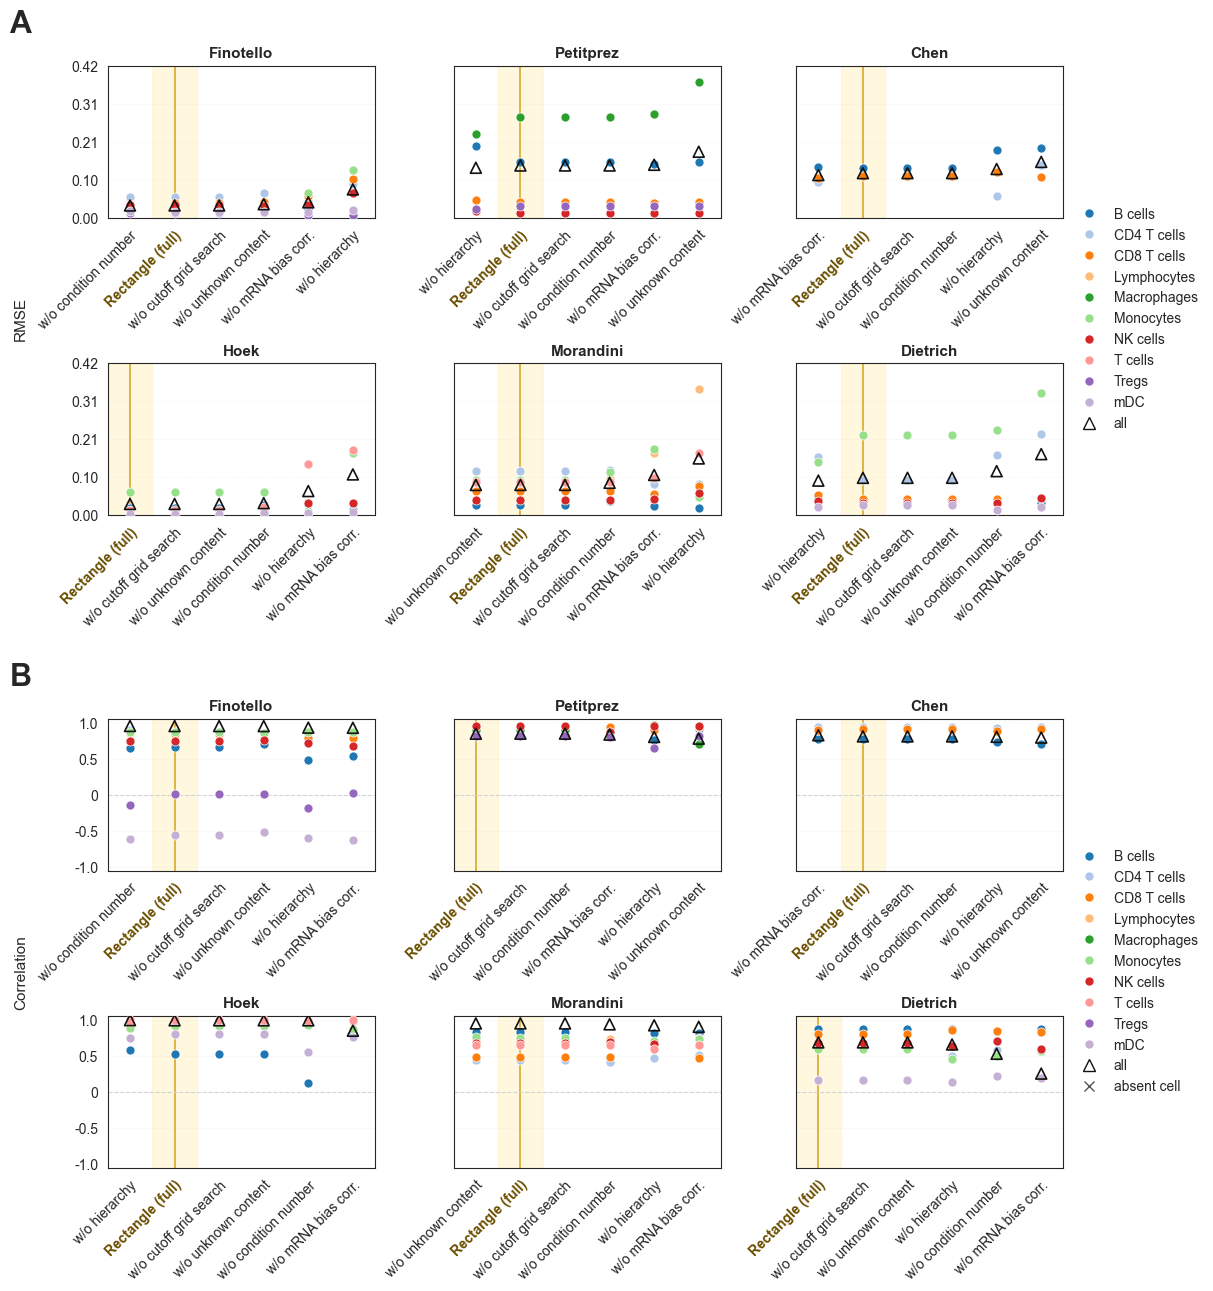

In [4]:
# Same layout as fig_suppl1_celltype_method_rmse_correlation (figure_2.ipynb), with ablations in place of methods
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

ablation_labels = {
    'full': 'Rectangle (full)',
    'no_mrna_bias': 'w/o mRNA bias corr.',
    'no_grid_search': 'w/o cutoff grid search',
    'no_unknown': 'w/o unknown content',
    'no_hierarchy': 'w/o hierarchy',
    'no_condition_number': 'w/o condition number',
}
bulk_labels = {
    'finotello': 'Finotello',
    'petitprez': 'Petitprez',
    'chen': 'Chen',
    'hoek': 'Hoek',
    'morandini': 'Morandini',
    'dietrich': 'Dietrich',
}
# True: order ablations per panel by their 'all' value, as in the methods figure; False: same order in every panel
sort_by_overall = True

df_plot = pd.read_csv(ablation_root / 'celltype_metrics.csv')
plot_ablations = [a for a in ablation_order if a in set(df_plot['ablation'])]
plot_datasets = [d for d in dataset_order if d in set(df_plot['bulk_ds'])]

cell_type_order = sorted([ct for ct in df_plot['cell_type'].dropna().unique() if ct != 'all']) + ['all']
palette = dict(zip(cell_type_order, sns.color_palette('tab20', n_colors=len(cell_type_order))))
palette['all'] = '#111111'

plot_specs = [
    ('RMSE', 'RMSE', 'A'),
    ('cor', 'Correlation', 'B'),
]
combined_out_path = '../figures/fig_suppl_ablation_celltype_rmse_correlation'

n_cols = 3
n_rows = int(np.ceil(len(plot_datasets) / n_cols))
fig = plt.figure(figsize=(4.0 * n_cols, (2.6 * n_rows + 1.2) * len(plot_specs)), facecolor='white', layout='constrained')
subfigs = fig.subfigures(len(plot_specs), 1, hspace=0.04)

for subfig, (metric_col, y_label, panel_letter) in zip(subfigs, plot_specs):
    ascending = metric_col == 'RMSE'

    subfig.set_facecolor('white')
    axes = subfig.subplots(n_rows, n_cols, sharey=True)
    axes = np.array(axes).reshape(-1)

    metric_max = float(df_plot[metric_col].max(skipna=True))
    if metric_col == 'cor':
        y_lim = (-1.05, 1.05)
        y_ticks = list(np.linspace(-1, 1, 5))
        y_tick_labels = [f'{v:.1f}' if v != 0 else '0' for v in y_ticks]
    else:
        y_lim = (0, max(metric_max * 1.12, 0.1))
        y_ticks = list(np.linspace(0, y_lim[1], 5))
        y_tick_labels = [f'{v:.2f}' for v in y_ticks]

    for i, (ax, bulk) in enumerate(zip(axes, plot_datasets)):
        ax.set_facecolor('white')
        # with a fixed order the ablation names are only needed on the bottom panel of each column
        show_labels = sort_by_overall or i + n_cols >= len(plot_datasets)
        sub = df_plot[df_plot['bulk_ds'] == bulk]
        plot_ablation_order = plot_ablations
        if sort_by_overall:
            all_metric = sub[sub['cell_type'] == 'all'].set_index('ablation')[metric_col].reindex(plot_ablations)
            plot_ablation_order = all_metric.sort_values(ascending=ascending).index.tolist()
        if 'full' in plot_ablation_order:
            full_idx = plot_ablation_order.index('full')
            ax.axvspan(full_idx - 0.5, full_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
            ax.axvline(full_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

        for ct in cell_type_order:
            d_ct = sub[sub['cell_type'] == ct]
            if d_ct.empty:
                continue
            x_vals = np.array([plot_ablation_order.index(a) for a in d_ct['ablation']], dtype=int)
            y_vals = d_ct[metric_col]
            marker_style = '^' if ct == 'all' else 'o'
            marker_size = 62 if ct == 'all' else 42
            face_color = 'none' if ct == 'all' else palette[ct]
            edge_color = '#111111' if ct == 'all' else 'white'
            line_width = 1.2 if ct == 'all' else 0.5

            valid_mask = y_vals.notna().to_numpy()
            if valid_mask.any():
                ax.scatter(
                    x_vals[valid_mask],
                    y_vals.to_numpy()[valid_mask],
                    s=marker_size,
                    marker=marker_style,
                    facecolors=face_color,
                    edgecolors=edge_color,
                    linewidths=line_width,
                    zorder=3
                )
            if metric_col == 'cor' and (~valid_mask).any():
                nan_y = y_lim[0] + 0.03
                nan_marker_color = '#111111' if ct == 'all' else palette[ct]
                ax.scatter(
                    x_vals[~valid_mask],
                    np.full((~valid_mask).sum(), nan_y, dtype=float),
                    s=30,
                    marker='x',
                    color=nan_marker_color,
                    linewidths=1.1,
                    zorder=4,
                )

        if metric_col == 'cor':
            ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_title(bulk_labels[bulk], fontsize=11, weight='bold')
        ax.set_xlim(-0.5, len(plot_ablation_order) - 0.5)
        ax.set_ylim(*y_lim)
        ax.set_xticks(range(len(plot_ablation_order)))
        ax.set_xticklabels([ablation_labels[a] if show_labels else '' for a in plot_ablation_order],
                           rotation=45, ha='right', rotation_mode='anchor')
        for lbl, a in zip(ax.get_xticklabels(), plot_ablation_order):
            if a == 'full':
                lbl.set_fontweight('bold')
                lbl.set_color('#6b4f00')
        ax.grid(axis='y', linestyle=':', alpha=0.35)

    for ax in axes[:len(plot_datasets)]:
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(y_tick_labels)
    for ax in axes[len(plot_datasets):]:
        ax.axis('off')

    subfig.supylabel(y_label, fontsize=11)
    subfig.suptitle(panel_letter, x=0.0, ha='left', fontsize=22, fontweight='bold')
    legend_handles = [
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='none', markeredgecolor='#111111', markersize=8, label='all') if ct == 'all'
        else Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=palette[ct], markeredgecolor='white', markersize=7, label=ct)
        for ct in cell_type_order
    ]
    if metric_col == 'cor':
        legend_handles.append(
            Line2D([0], [0], marker='x', linestyle='None', color='#555555', markersize=7, label='absent cell')
        )
    spare_axes = axes[len(plot_datasets):]
    if len(spare_axes):
        spare_axes[0].legend(handles=legend_handles, loc='center', ncol=2, frameon=False,
                             handletextpad=0.4, columnspacing=1.2, labelspacing=0.7)
    else:
        subfig.legend(handles=legend_handles, loc='outside right center', frameon=False)

for ext in ('pdf', 'png'):
    fig.savefig(f'{combined_out_path}.{ext}', facecolor='white', bbox_inches='tight', dpi=300)
plt.show()